# LDA Deck-Level Model — Deck Granularity
**Modeling**

Implements LDA at slide-deck level following the CRISP-DM modeling phase.  
Library: `gensim` (Variational Bayes).  
Input: deck-level token lists produced by `src/utils.py`.  
Granularity: one document = one full slide deck (all pages of one lecture PDF aggregated).  
Corpus size: 9 documents (one per IDS lecture PDF).  
Split: leave-one-out holdout (8 train / 1 test, `random_state=42`).

> **Statistical constraint.** With 9 documents LDA operates below its typical minimum corpus
> requirements. Document-topic distributions carry high uncertainty; results should be
> interpreted as exploratory curriculum-level thematic profiles, not statistically stable
> topic models. See Section 6 for a full discussion.

**Structure:**
1. Setup & Data Loading
2. Corpus Preparation (dictionary + BoW + train/test split)
3. Model Training
4. Topic Inspection
5. Initial Evaluation (C_v)
6. Grid Search — Finding the Best K
7. Cross-library Comparison
8. Final Evaluation (C_v, perplexity, diversity, cosine similarity, entropy, exclusivity)

## 1. Setup & Data Loading

In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

_nb_dir = os.path.dirname(os.path.abspath('lda.ipynb'))
_src_dir = os.path.abspath(os.path.join(_nb_dir, '..'))
if _src_dir not in sys.path:
    sys.path.insert(0, _src_dir)

warnings.filterwarnings('ignore')

# Plotting defaults
plt.rcParams.update({
    'figure.dpi'       : 130,
    'axes.spines.top'  : False,
    'axes.spines.right': False,
    'axes.titlesize'   : 13,
    'axes.labelsize'   : 11,
    'font.family'      : 'serif',
})
PALETTE = ['#2C5F8A', '#4C9BE8', '#A8C8E8', '#D9E8F5']

print('Libraries loaded.')

Libraries loaded.


In [2]:
from utils import load_corpus, tokenize_corpus, build_slide_deck_docs

# Load and Tokenize corpus
corpus = tokenize_corpus(load_corpus())

# Aggregate to deck level. One document per slide PDF.
docs = build_slide_deck_docs(corpus)

print(f'Documents (decks): {len(docs)}')
print(f'Token count — min: {docs.n_tokens.min()}, median: {docs.n_tokens.median():.0f}, max: {docs.n_tokens.max()}')
docs[['source_file', 'n_tokens']]

Documents (decks): 9
Token count — min: 58, median: 410, max: 669


,source_file,n_tokens
0,icd_1_v1_cleaned_v7.csv,488
1,icd_2_v1_cleaned_v7.csv,568
2,icd_3_v1_cleaned_v7.csv,669
3,icd_4_v1_cleaned_v7.csv,230
4,icd_5_v1_cleaned_v7.csv,58
5,icd_6_v1_cleaned_v7.csv,410
6,icd_7_v1_cleaned_v7.csv,523
7,icd_8_v1_cleaned_v7.csv,130
8,icd_9_v1_cleaned_v7.csv,270


## 2. Corpus Preparation

In [3]:
import gensim
import gensim.corpora as corpora
from gensim.models import CoherenceModel

RANDOM_SEED = 42

texts = docs['tokens'].tolist()

# no_above relaxed to 0.9: with 9 docs the 0.8 ceiling is too aggressive (conservative thresholds)
dictionary = corpora.Dictionary(texts)
dictionary.filter_extremes(no_below=2, no_above=0.9)
dictionary.compactify()

bow_corpus = [dictionary.doc2bow(text) for text in texts]

print(f'Vocabulary size (after filtering): {len(dictionary)}')
print(f'Corpus size: {len(bow_corpus)} documents')
print(f'gensim version: {gensim.__version__}')

Vocabulary size (after filtering): 335
Corpus size: 9 documents
gensim version: 4.4.0


In [4]:
from sklearn.model_selection import train_test_split

# With only 9 deck-level documents, a 90/10 split yields 0 test docs.
# Use 1 doc as holdout (leave-one-out): 8 train / 1 test.
train_docs, test_docs = train_test_split(docs, test_size=1, random_state=RANDOM_SEED)
train_docs = train_docs.reset_index(drop=True)
test_docs  = test_docs.reset_index(drop=True)

train_texts = train_docs['tokens'].tolist()
test_texts  = test_docs['tokens'].tolist()

# Rebuild dictionary and BoW corpus from train set only
dictionary = corpora.Dictionary(train_texts)
dictionary.filter_extremes(no_below=2, no_above=0.9)
dictionary.compactify()

bow_corpus = [dictionary.doc2bow(text) for text in train_texts]
test_bow   = [dictionary.doc2bow(text) for text in test_texts]


print(f'Train: {len(train_texts)} docs | Test: {len(test_texts)} docs')

Train: 8 docs | Test: 1 docs


## 3. Model Training

In [5]:
from gensim.models import LdaModel

# k=5: must stay below n_docs (9); 5 allows meaningful separation without overfitting
NUM_TOPICS  = 5
PASSES      = 30   # more passes to compensate for small corpus
ITERATIONS  = 500
ALPHA       = 0.1
ETA         = 0.01

lda = LdaModel(
    corpus          = bow_corpus,
    id2word         = dictionary,
    num_topics      = NUM_TOPICS,
    passes          = PASSES,
    iterations      = ITERATIONS,
    alpha           = ALPHA,
    eta             = ETA,
    random_state    = RANDOM_SEED,
    per_word_topics = True,
)

print(f'LDA trained: {NUM_TOPICS} topics, {PASSES} passes, seed={RANDOM_SEED}')

LDA trained: 5 topics, 30 passes, seed=42


## 4. Topic Inspection

In [6]:
# Top terms per topic
TOP_N = 10
for i, topic in lda.print_topics(num_topics=NUM_TOPICS, num_words=TOP_N):
    print(f'Topic {i:02d}: {topic}')

Topic 00: 0.029*"volume" + 0.029*"padrão" + 0.029*"tratamento" + 0.025*"europeu" + 0.025*"empresa" + 0.025*"modelo" + 0.021*"artificial" + 0.017*"população" + 0.017*"conteúdo" + 0.017*"pessoa"
Topic 01: 0.065*"variável" + 0.060*"valores" + 0.036*"atributo" + 0.029*"categórico" + 0.027*"classificação" + 0.024*"processo" + 0.021*"numérico" + 0.020*"target" + 0.020*"features" + 0.018*"aluno"
Topic 02: 0.085*"modelo" + 0.033*"resultado" + 0.029*"objetivo" + 0.028*"aprendizagem" + 0.024*"previsão" + 0.023*"conjunto" + 0.022*"variável" + 0.021*"treino" + 0.018*"avaliação" + 0.017*"decisão"
Topic 03: 0.035*"visualização" + 0.028*"conhecimento" + 0.026*"imagem" + 0.024*"texto" + 0.024*"análise" + 0.020*"projeto" + 0.017*"contexto" + 0.015*"processo" + 0.013*"conteúdo" + 0.013*"objetivo"
Topic 04: 0.061*"utilização" + 0.061*"visualização" + 0.061*"componente" + 0.061*"widget" + 0.061*"ligação" + 0.030*"utilizador" + 0.030*"input" + 0.030*"ferramenta" + 0.030*"mining" + 0.030*"automático"


In [7]:
from utils import generate_topic_labels_llm

TOPIC_LABELS = generate_topic_labels_llm(lda, NUM_TOPICS)

for idx, label in TOPIC_LABELS.items():
    print(f'T{idx:02d}: {label}')

T00: Dados empresariais padrões
T01: Modelagem supervisionada
T02: Modelação supervisionada
T03: Visualização de Dados
T04: Ferramenta Orange Visualização


In [8]:
# Topic summary table
rows = []
for i in range(NUM_TOPICS):
    terms = lda.show_topic(i, topn=TOP_N)
    top_words   = ', '.join(w for w, _ in terms)
    top_weights = [round(p, 3) for _, p in terms]
    rows.append({
        'Topic'     : f'T{i:02d}',
        'Label'     : TOPIC_LABELS[i],
        'Top 10 Terms': top_words,
        'Max weight': max(top_weights),
    })

topic_df = pd.DataFrame(rows).set_index('Topic')

topic_df.style \
    .set_caption('LDA Topics — Top 10 Terms per Topic (gensim, deck-level)') \
    .set_properties(**{'text-align': 'left'}) \
    .bar(subset=['Max weight'], color='#0156AB', vmin=0, vmax=0.15)

,Label,Top 10 Terms,Max weight
Topic,,,
T00,Dados empresariais padrões,"volume, padrão, tratamento, europeu, empresa, modelo, artificial, população, conteúdo, pessoa",0.029000
T01,Modelagem supervisionada,"variável, valores, atributo, categórico, classificação, processo, numérico, target, features, aluno",0.065000
T02,Modelação supervisionada,"modelo, resultado, objetivo, aprendizagem, previsão, conjunto, variável, treino, avaliação, decisão",0.085000
T03,Visualização de Dados,"visualização, conhecimento, imagem, texto, análise, projeto, contexto, processo, conteúdo, objetivo",0.035000
T04,Ferramenta Orange Visualização,"utilização, visualização, componente, widget, ligação, utilizador, input, ferramenta, mining, automático",0.061000


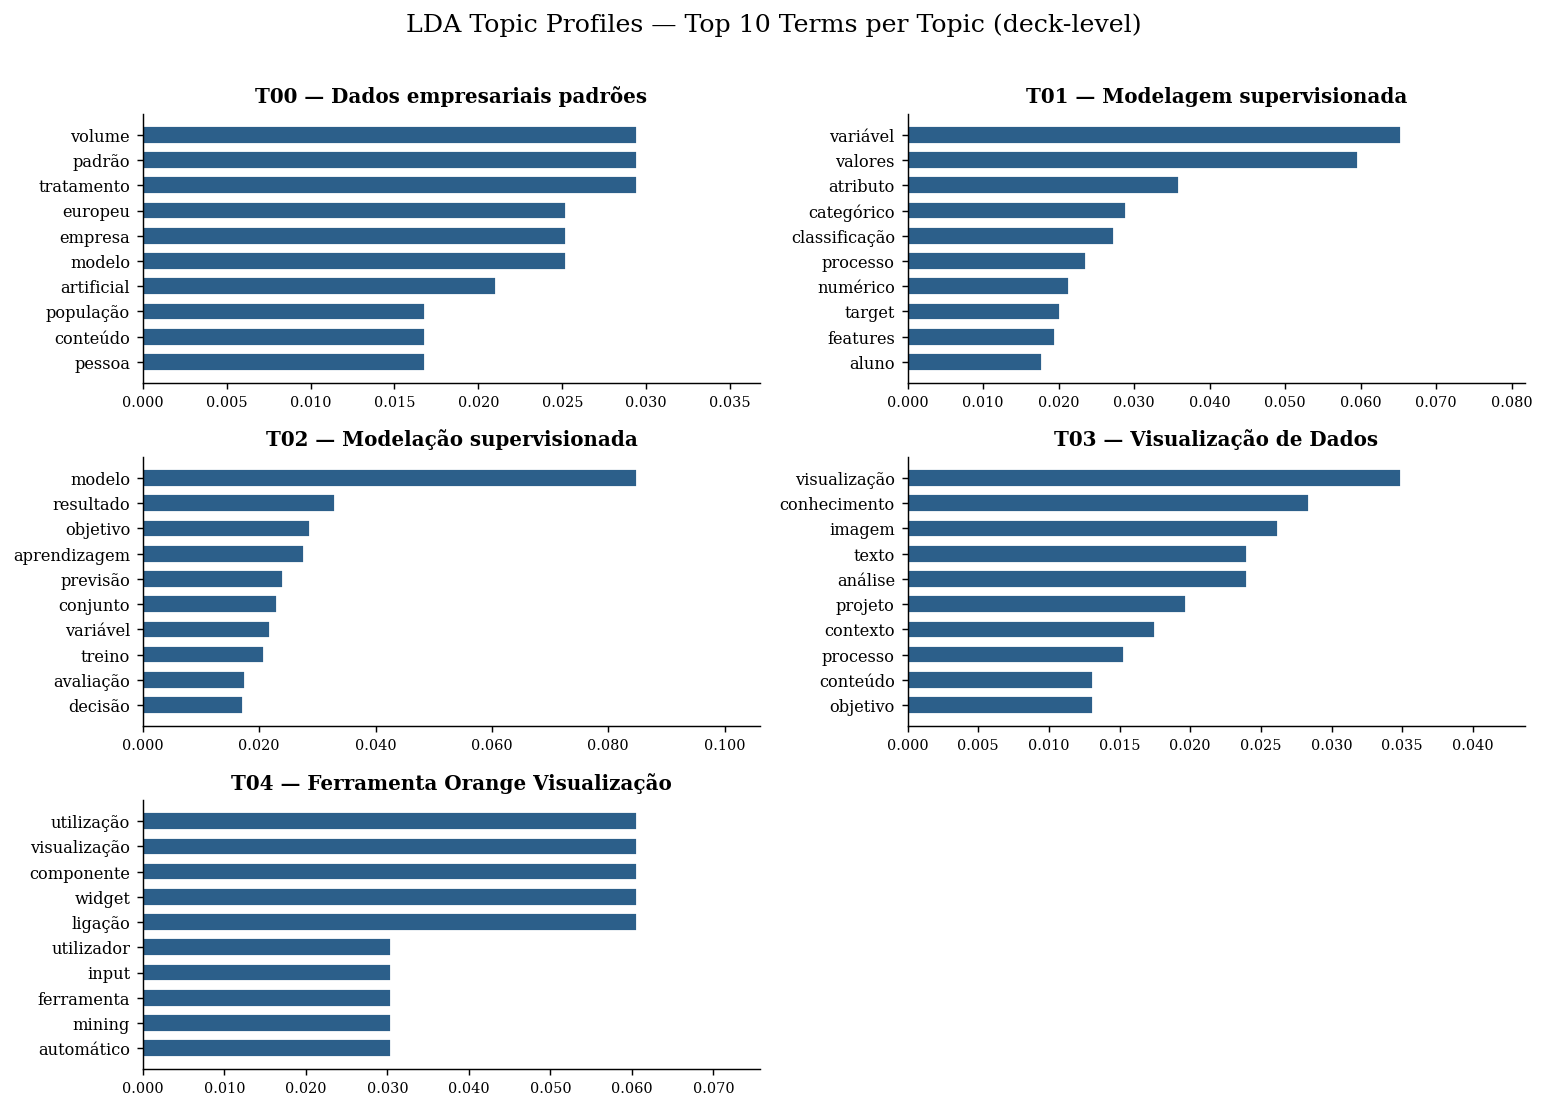

In [9]:
# Visualize topic profiles
TOP_VIS = 10
n_cols = 2
n_rows = (NUM_TOPICS + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, n_rows * 2.8))
axes = axes.flatten()

for i in range(NUM_TOPICS):
    terms   = lda.show_topic(i, topn=TOP_VIS)
    words   = [w for w, _ in terms][::-1]
    weights = [p for _, p in terms][::-1]

    ax = axes[i]
    ax.barh(words, weights, color=PALETTE[0], edgecolor='white', height=0.7)
    ax.set_title(f'T{i:02d} — {TOPIC_LABELS[i]}', fontsize=11, fontweight='bold')
    ax.set_xlim(0, max(weights) * 1.25)
    ax.tick_params(axis='y', labelsize=9)
    ax.tick_params(axis='x', labelsize=8)
    ax.xaxis.set_major_formatter(mticker.FormatStrFormatter('%.3f'))

for j in range(NUM_TOPICS, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('LDA Topic Profiles — Top 10 Terms per Topic (deck-level)', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

               source_file  n_tokens  dominant_topic
0  icd_2_v1_cleaned_v7.csv       568               0
1  icd_6_v1_cleaned_v7.csv       410               1
2  icd_1_v1_cleaned_v7.csv       488               3
3  icd_9_v1_cleaned_v7.csv       270               3
4  icd_3_v1_cleaned_v7.csv       669               2
5  icd_5_v1_cleaned_v7.csv        58               4
6  icd_4_v1_cleaned_v7.csv       230               3
7  icd_7_v1_cleaned_v7.csv       523               1


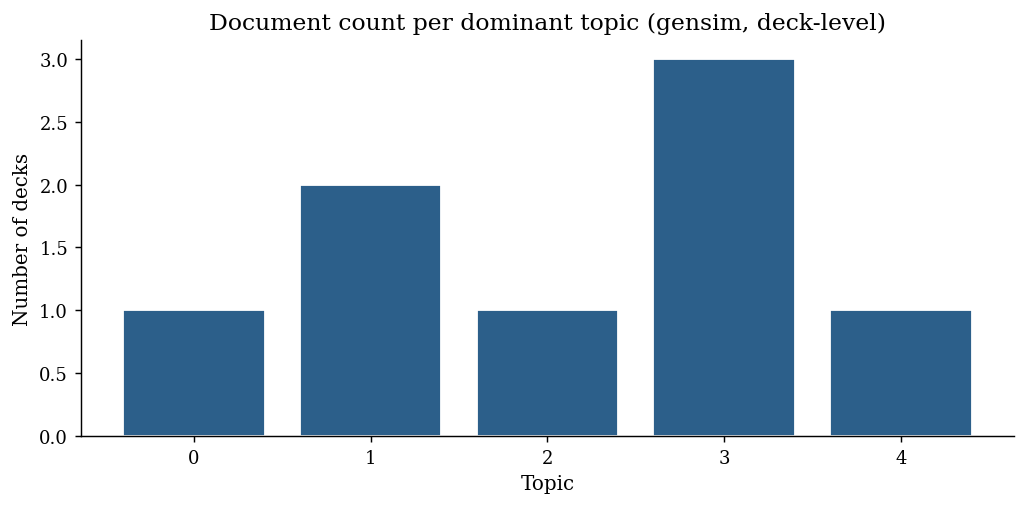

In [10]:
# Visualize document-topic distribution
train_docs_plot = train_docs.copy()
train_docs_plot['dominant_topic'] = [
    max(lda.get_document_topics(b), key=lambda x: x[1])[0] if lda.get_document_topics(b) else -1
    for b in bow_corpus
]

print(train_docs_plot[['source_file', 'n_tokens', 'dominant_topic']].to_string())

topic_dist = train_docs_plot['dominant_topic'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(topic_dist.index, topic_dist.values, color=PALETTE[0], edgecolor='white')
ax.set_xlabel('Topic')
ax.set_ylabel('Number of decks')
ax.set_title('Document count per dominant topic (gensim, deck-level)')
ax.set_xticks(range(NUM_TOPICS))
plt.tight_layout()
plt.show()

## 5. Initial Evaluation (C_v)

In [11]:
coherence_model = CoherenceModel(
    model=lda,
    texts=train_texts,
    dictionary=dictionary,
    coherence='c_v',
)
coherence_cv = coherence_model.get_coherence()

print(f'Coherence (C_v): {coherence_cv:.4f}  (target > 0.50)')

Coherence (C_v): 0.3747  (target > 0.50)


## 6. Grid Search — Finding the Best K

K initial = 5 (must stay below n_docs=9; conservative starting point).  
Grid search over K ∈ [2, 8] to find the C_v-optimal K for this library.  
The best K from each library will be used in the cross-library comparison (Section 7).

k= 2  C_v=0.3930
k= 3  C_v=0.4221
k= 4  C_v=0.4060
k= 5  C_v=0.3747
k= 6  C_v=0.3541
k= 7  C_v=0.4068
k= 8  C_v=0.4099
k= 9  C_v=0.4134


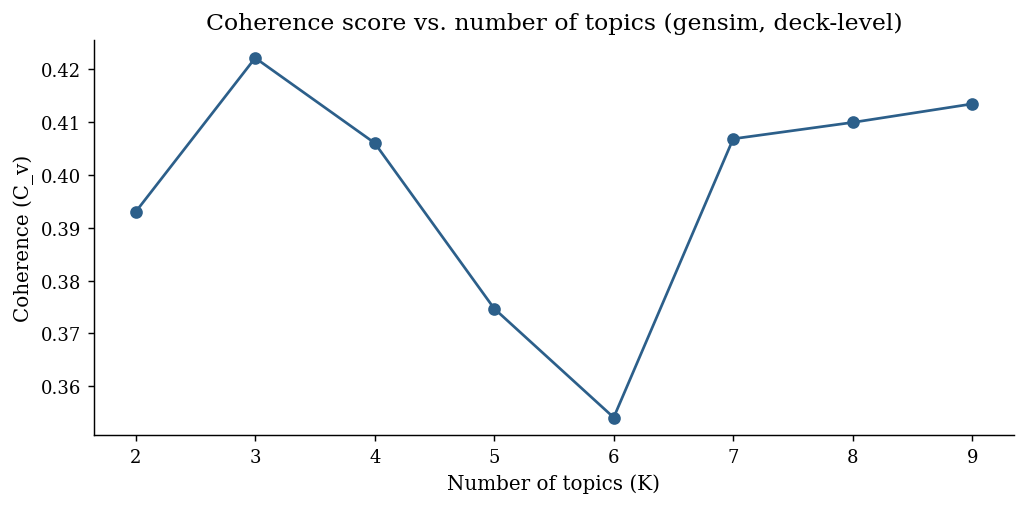


Best k=3  C_v=0.4221


In [12]:
# Coherence grid search over number of topics
# Helps to find the optimal K before committing to a final model and parameters.
TOPIC_RANGE = range(2, 10)

results = []
for k in TOPIC_RANGE:
    m = LdaModel(
        corpus       = bow_corpus,
        id2word      = dictionary,
        num_topics   = k,
        passes       = PASSES,
        iterations   = ITERATIONS,
        alpha        = ALPHA,
        eta          = ETA,
        random_state = RANDOM_SEED,
    )
    cv = CoherenceModel(model=m, texts=train_texts, dictionary=dictionary, coherence='c_v').get_coherence()
    results.append({'k': k, 'coherence_cv': round(cv, 4)})
    print(f'k={k:2d}  C_v={cv:.4f}')

results_df = pd.DataFrame(results)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(results_df['k'], results_df['coherence_cv'], marker='o', color=PALETTE[0])
ax.set_xlabel('Number of topics (K)')
ax.set_ylabel('Coherence (C_v)')
ax.set_title('Coherence score vs. number of topics (gensim, deck-level)')
ax.set_xticks(list(TOPIC_RANGE))
plt.tight_layout()
plt.show()

best = results_df.loc[results_df['coherence_cv'].idxmax()]
print(f'\nBest k={int(best.k)}  C_v={best.coherence_cv}')

## 7. Cross-library Comparison

Trains models at two K values to compare how each library responds to K choices:
- **K_INITIAL**: domain-informed starting point
- **K_VB_BEST**: optimal K found by gensim VB grid search

> **Note:** At deck level both libraries converge on K=3, so cross-library K cross-application yields the same K_CGS_BEST = K_VB_BEST = 3.

In [13]:
K_INITIAL  = 5   # domain-informed prior: stay below n_docs (9)
K_CGS_BEST = 3   # tomotopy CGS grid search optimum (same K at deck level)
K_VB_BEST  = 3   # gensim VB grid search optimum (C_v peak)

K_GRID = [K_INITIAL, K_VB_BEST]

models_by_k = {}
for k in K_GRID:
    m = LdaModel(
        corpus       = bow_corpus,
        id2word      = dictionary,
        num_topics   = k,
        passes       = PASSES,
        iterations   = ITERATIONS,
        alpha        = ALPHA,
        eta          = ETA,
        random_state = RANDOM_SEED,
    )
    models_by_k[k] = m
    cv = CoherenceModel(model=m, texts=train_texts, dictionary=dictionary, coherence='c_v').get_coherence()
    print(f'Trained gensim VB  k={k}  C_v={cv:.4f}')

print('\nCross-library C_v summary:')
for label, k in [('K_INITIAL', K_INITIAL), ('K_VB_BEST (= K_CGS_BEST)', K_VB_BEST)]:
    cv = CoherenceModel(model=models_by_k[k], texts=train_texts, dictionary=dictionary, coherence='c_v').get_coherence()
    print(f'  {label} (k={k}): C_v = {cv:.4f}')

Trained gensim VB  k=5  C_v=0.3747
Trained gensim VB  k=3  C_v=0.4221

Cross-library C_v summary:
  K_INITIAL (k=5): C_v = 0.3747
  K_VB_BEST (= K_CGS_BEST) (k=3): C_v = 0.4221


## 8. Final Evaluation

Evaluates the best model found by the grid search (K_VB_BEST=3) with all metrics:
- **C_v coherence** (primary)
- **Train and test perplexity**
- **U_mass coherence**, **topic diversity**, **cosine similarity**, **Shannon entropy**, **exclusivity**

In [14]:
best_model = models_by_k[K_VB_BEST]

# C_v coherence
best_cv = CoherenceModel(model=best_model, texts=train_texts, dictionary=dictionary, coherence='c_v').get_coherence()
print(f'Best model (k={K_VB_BEST}) — C_v: {best_cv:.4f}')

# Train perplexity — gensim native (in-sample)
train_perplexity = np.exp(-best_model.log_perplexity(bow_corpus))
print(f'Best model (k={K_VB_BEST}) — Train Perplexity: {train_perplexity:.2f}')

# Test perplexity — gensim VB variational bound (not directly comparable with CGS)
per_word_bound  = best_model.log_perplexity(test_bow)
test_perplexity = np.exp(-per_word_bound)
print(f'Best model (k={K_VB_BEST}) — Test Perplexity: {test_perplexity:.2f}  (variational bound; not comparable with CGS)')

Best model (k=3) — C_v: 0.4221
Best model (k=3) — Train Perplexity: 560.03
Best model (k=3) — Test Perplexity: 178846899925662848.00  (variational bound; not comparable with CGS)


### 8.1 U_mass Coherence

In [15]:
from gensim.models import CoherenceModel

cm_umass = CoherenceModel(
    model=best_model,
    corpus=bow_corpus,
    dictionary=dictionary,
    coherence='u_mass',
)
coherence_umass = cm_umass.get_coherence()

print(f'Best model (k={K_VB_BEST}) — U_mass: {coherence_umass:.4f}  (closer to 0 = better; range typically −14 to 0)')

Best model (k=3) — U_mass: -0.8636  (closer to 0 = better; range typically −14 to 0)


In [16]:
# Topic diversity: fraction of unique words across top-N words of all topics
# Dieng et al. (2020) — range [0, 1]; higher = less redundancy between topics
TOP_N_DIV = 25

all_top_words = []
for i in range(K_VB_BEST):
    terms = best_model.show_topic(i, topn=TOP_N_DIV)
    all_top_words.extend([w for w, _ in terms])

diversity = len(set(all_top_words)) / len(all_top_words)
print(f'Best model (k={K_VB_BEST}) — Topic Diversity (top-{TOP_N_DIV}): {diversity:.4f}  (range 0–1; higher = more diverse)')

Best model (k=3) — Topic Diversity (top-25): 0.8267  (range 0–1; higher = more diverse)


In [17]:
# Mean pairwise cosine similarity over top-N topic word-probability vectors
# Lower = more distinct topics; range [0, 1]
from itertools import combinations
import numpy as np

TOP_N_COS = 10
vocab_size = len(dictionary)

# Build topic vectors (full vocab, probability at each position)
topic_vectors = []
for i in range(K_VB_BEST):
    vec = np.zeros(vocab_size)
    for w, p in best_model.show_topic(i, topn=TOP_N_COS):
        if w in dictionary.token2id:
            vec[dictionary.token2id[w]] = p
    topic_vectors.append(vec)

sims = []
for a, b in combinations(topic_vectors, 2):
    cos = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-10)
    sims.append(cos)

mean_cos = np.mean(sims)
max_cos  = np.max(sims)
print(f'Best model (k={K_VB_BEST}) — Cosine Similarity (top-{TOP_N_COS}): mean={mean_cos:.4f}, max={max_cos:.4f}  (lower = more distinct)')

Best model (k=3) — Cosine Similarity (top-10): mean=0.0533, max=0.1104  (lower = more distinct)


In [18]:
# Shannon entropy of topic-word distributions
# Higher = more diffuse topic; lower = more concentrated/specific
from scipy.stats import entropy as shannon_entropy

entropies = []
for i in range(K_VB_BEST):
    probs = best_model.get_topics()[i]  # full vocab distribution, shape (vocab_size,)
    probs = probs / probs.sum()
    entropies.append(shannon_entropy(probs))

mean_ent = np.mean(entropies)
print(f'Best model (k={K_VB_BEST}) — Shannon Entropy: mean={mean_ent:.4f}  (higher = more diffuse)')
for i, e in enumerate(entropies):
    print(f'  T{i+1}: {e:.4f}')

Best model (k=3) — Shannon Entropy: mean=4.8410  (higher = more diffuse)
  T1: 5.1168
  T2: 4.6682
  T3: 4.7381


In [19]:
# Exclusivity: mean P(topic|word) over top-N words per topic
# Higher = words concentrated in that topic alone; lower = words shared across topics
TOP_N_EXC = 10

# Compute P(word|topic) matrix for all topics
topic_word_matrix = best_model.get_topics()  # shape (k, vocab_size)
# P(topic|word) via Bayes: normalise across topics for each word
topic_given_word = topic_word_matrix / (topic_word_matrix.sum(axis=0, keepdims=True) + 1e-10)

exclusivities = []
for i in range(K_VB_BEST):
    top_indices = topic_word_matrix[i].argsort()[-TOP_N_EXC:]
    excl = topic_given_word[i, top_indices].mean()
    exclusivities.append(excl)

mean_excl = np.mean(exclusivities)
print(f'Best model (k={K_VB_BEST}) — Exclusivity (top-{TOP_N_EXC}): mean={mean_excl:.4f}  (higher = more exclusive)')
for i, e in enumerate(exclusivities):
    print(f'  T{i+1}: {e:.4f}')

Best model (k=3) — Exclusivity (top-10): mean=0.7259  (higher = more exclusive)
  T1: 0.7112
  T2: 0.7097
  T3: 0.7569


### 8.6 Evaluation Summary

In [20]:
summary = {
    'Metric': ['C_v', 'U_mass', 'Train Perplexity', 'Test Perplexity',
               'Diversity (top-25)', 'Cosine Sim (mean)', 'Shannon Entropy', 'Exclusivity (top-10)'],
    'VB k=3': [f'{best_cv:.2f}', f'{coherence_umass:.2f}', f'{train_perplexity:.2f}',
               f'{test_perplexity:.2e} (†)', f'{diversity:.2f}', f'{mean_cos:.3f}',
               f'{mean_ent:.2f}', f'{mean_excl:.2f}'],
    'Direction': ['higher', 'closer to 0', 'lower', 'lower', 'higher', 'lower', 'lower', 'higher'],
}

summary_df = pd.DataFrame(summary).set_index('Metric')
summary_df.style.set_caption('† VB test perplexity uses variational bound — not comparable with CGS')

,VB k=3,Direction
Metric,,
C_v,0.42,higher
U_mass,-0.86,closer to 0
Train Perplexity,560.03,lower
Test Perplexity,1.79e+17 (†),lower
Diversity (top-25),0.83,higher
Cosine Sim (mean),0.053,lower
Shannon Entropy,4.84,lower
Exclusivity (top-10),0.73,higher
